In [1]:
# Consider a thin, square metal plate of dimensions 1 m x 1 m:
#     - The plate generates heat uniformly due to an internal heat sources.
#     - The left, right, top and bottom edges are maintained at 0 degrees C.
#     - The plate has thermal conductivity k = 10 W / (m . K)
#     - The uniform heat generation rate is q''' = 1000 W / m^3
#     - Assume steady-state heat conduction.
# Find the temperature distribution throughout the plate and determine the temperature at its centre.
# Use a 5 x 5 grid for manual verification.

In [2]:
#for two dimensional heat conduction: curl^2 T / curl x^2 + curl^2 T / curl y^2 = - q''' / k

#Poisson Equation

#Finite Difference Method (FDM)

#Calculation of electric potential between different charged boundaries

#Gauss-Seidel Iteration Method

import numpy as np
import matplotlib.pyplot as plt

#define grid
Lx = 1
Ly = 1
Nx = 5
Ny = 5

dx = Lx / (Nx - 1)
dy = Ly / (Ny - 1)

x = np.linspace(0, Lx, Nx)
y = np.linspace(0, Ly, Ny)

X, Y = np.meshgrid(x, y)

In [3]:
#initialize potential

q = 1000
k = 10

T = np.zeros((Ny, Nx))

T_top = 0
T_bottom = 0
T_left = 0
T_right = 0

T[-1, :] = T_top
T[0, :] = T_bottom
T[:, 0] = T_left
T[:, -1] = T_right

In [4]:
#Gauss-Seidel Iteration

tol = 1e-10
max_itr = 20000

for itr in range(max_itr):
    max_err = 0
    for j in range(1, Ny - 1):
        for i in range(1, Nx - 1):
            old_value = T[j, i]
            T[j, i] = ( (T[j, i+1] + T[j, i-1]) / dx**2 + (T[j+1, i] + T[j-1, i]) / dy**2 + q / k ) / ( 2 / dx**2 + 2 / dy**2)
            err = abs(T[j, i] - old_value)
            max_err = max(max_err, err)
    if(max_err < tol):
        break

print('Iterations:', itr + 1)
print('Max Error:', max_err)

Iterations: 37
Max Error: 7.105427357601002e-11


In [6]:
print("Temperature Distribution (V):\n", np.round(T, 2))
print("Central Temperature:", T[Ny//2, Nx//2], "degrees C")

Temperature Distribution (V):
 [[0.   0.   0.   0.   0.  ]
 [0.   4.3  5.47 4.3  0.  ]
 [0.   5.47 7.03 5.47 0.  ]
 [0.   4.3  5.47 4.3  0.  ]
 [0.   0.   0.   0.   0.  ]]
Central Temperature: 7.031249999928946 degrees C


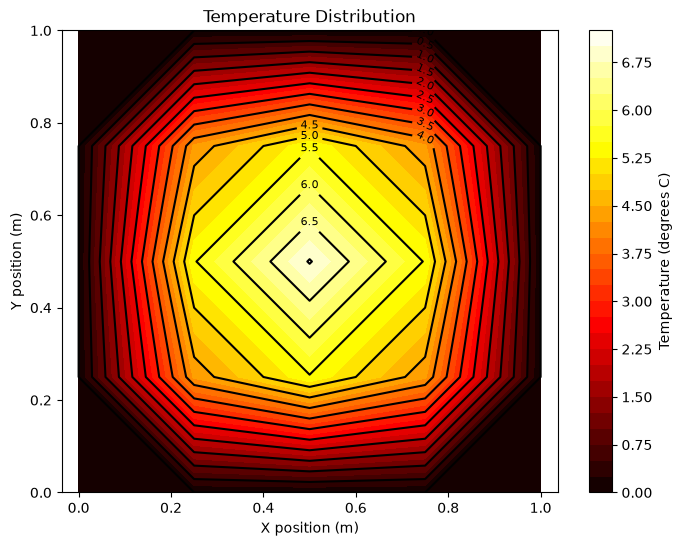

In [8]:
#temperature distribution plot

plt.figure(figsize=(8, 6))

contour = plt.contourf(X, Y, T, levels=30, cmap='hot')

plt.colorbar(contour, label='Temperature (degrees C)')

lines = plt.contour(X, Y, T, levels=15, colors='black')

plt.clabel(lines, inline=True, fontsize=8)

plt.xlabel('X position (m)')
plt.ylabel('Y position (m)')

plt.title('Temperature Distribution')

plt.axis('equal')
plt.show()